In [8]:
#23070521013 Amritansh Singh
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [2]:
import re
from google.colab import files

print("Please upload your historical stock data CSV file.")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded. Please upload a CSV file to proceed.")

# Get the filename of the uploaded file
file_name = list(uploaded.keys())[0]
print(f"Uploaded file: {file_name}")

# Load your actual stock data from the uploaded CSV file
df = pd.read_csv(file_name)

# Standardize column names and set 'Price'
# Assuming 'Date' is present and 'Close/Last' contains the relevant price data
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])
    df.set_index('Date', inplace=True)

# Identify and clean the 'Close/Last' column as 'Price'
if 'Close/Last' in df.columns:
    # Remove '$' and ',' from 'Close/Last' and convert to float
    df['Price'] = df['Close/Last'].astype(str).str.replace(r'[$,]', '', regex=True).astype(float)
    df = df[['Price']].copy() # Keep only the 'Price' column for consistency
elif 'Price' not in df.columns:
    print("Warning: Neither 'Close/Last' nor 'Price' column found. Please check your CSV and adjust the code.")
    print("Attempting to use the first numeric column found as 'Price'...")
    numeric_cols = df.select_dtypes(include=np.number).columns
    if len(numeric_cols) > 0:
        # Assuming the first numeric column after Date processing is the relevant price
        df.rename(columns={numeric_cols[0]: 'Price'}, inplace=True)
        df = df[['Price']].copy()
    else:
        raise ValueError("No suitable numeric column found to use as 'Price'.")

# Drop any rows with NaN values in the 'Price' column that might result from conversion issues
df.dropna(subset=['Price'], inplace=True)

print("Loaded stock data:")
display(df.head())
display(df.tail())

Please upload your historical stock data CSV file.


Saving HistoricalData_1787559716990.csv to HistoricalData_1787559716990.csv
Uploaded file: HistoricalData_1787559716990.csv
Loaded stock data:


,Price
Date,
2026-08-21,309.35
2026-08-20,311.30
2026-08-19,316.83
2026-08-18,310.03
2026-08-17,305.59


,Price
Date,
2026-07-30,333.43
2026-07-29,338.19
2026-07-28,340.08
2026-07-27,336.91
2026-07-24,333.02


In [3]:
# Normalize the data
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df['Price'].values.reshape(-1, 1))

# Print the length of the scaled data for clarity
print(f"Length of scaled data: {len(scaled_data)} rows")

# Create sequences for LSTM
def create_sequences(data, time_step):
    X, y = [], []
    for i in range(len(data) - time_step - 1):
        a = data[i:(i + time_step), 0]
        X.append(a)
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

# Adjust time_step based on data length. For demonstration, we'll use a small value.
# In a real scenario, you'd want significantly more data than time_step + 1.
# If len(scaled_data) is 21, and time_step = 5, then 21 - 5 - 1 = 15 iterations. This should work.
time_step = min(5, len(scaled_data) - 2) # Ensure time_step is at least 1, and fits the data
if time_step < 1:
    raise ValueError("Not enough data to create sequences. Need at least 3 data points.")

X, y = create_sequences(scaled_data, time_step)

# Check if X is empty after sequence creation
if X.size == 0:
    raise ValueError(f"No sequences could be created with time_step={time_step}. \n" +
                     f"Scaled data length: {len(scaled_data)}. \n" +
                     f"You need at least {time_step + 2} data points to create sequences.")

# Reshape X for LSTM input: [samples, time_steps, features]
X = X.reshape(X.shape[0], X.shape[1], 1)

print(f"Using time_step: {time_step}")
print(f"Shape of X (input sequences): {X.shape}")
print(f"Shape of y (target values): {y.shape}")

Length of scaled data: 21 rows
Using time_step: 5
Shape of X (input sequences): (15, 5, 1)
Shape of y (target values): (15,)


In [4]:
# Split data into training and testing sets
training_size = int(len(X) * 0.8)
test_size = len(X) - training_size
X_train, X_test = X[0:training_size,:], X[training_size:len(X),:]
y_train, y_test = y[0:training_size], y[training_size:len(y)]

print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (12, 5, 1)
y_train shape: (12,)
X_test shape: (3, 5, 1)
y_test shape: (3,)


In [5]:
# Build the LSTM model
model = Sequential()
model.add(LSTM(units=50, return_sequences=True, input_shape=(time_step, 1)))
model.add(Dropout(0.2))
model.add(LSTM(units=50, return_sequences=False))
model.add(Dropout(0.2))
model.add(Dense(units=1))

model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 5, 50)          │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 5, 50)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - loss: 0.0303 - val_loss: 0.3468
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 0.0267 - val_loss: 0.3340
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - loss: 0.0243 - val_loss: 0.3216
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - loss: 0.0216 - val_loss: 0.3092
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - loss: 0.0188 - val_loss: 0.2968
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 0.0171 - val_loss: 0.2845
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - loss: 0.0151 - val_loss: 0.2721
Epoch 8/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step - loss: 0.0135 - val_loss: 0.2598
Epoch 9/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step - loss: 0.0125 - val_loss: 0.2478
Epoch 10/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - loss: 0.0107 - val_loss: 0.2363
Epoch 11/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step - loss: 0.0103 - val_loss: 0.2258
Epoch 12/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step - loss: 0.0123 - val_loss: 0.2171
Ep

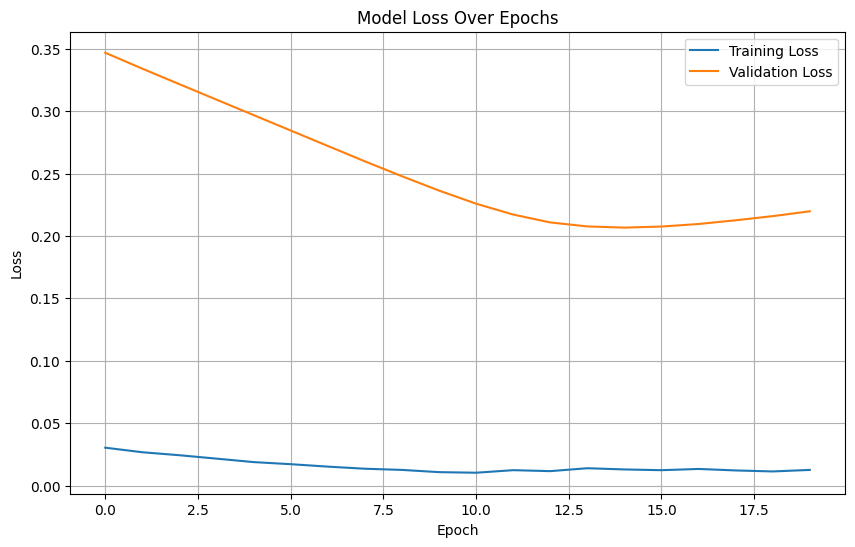

In [6]:
# Train the model
history = model.fit(X_train, y_train, epochs=20, batch_size=32, validation_split=0.1, verbose=1)

plt.figure(figsize=(10, 6))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

## Theory and Concepts (Concise)

### Recurrent Neural Networks (RNNs) and Long Short-Term Memory (LSTM)
*   **RNNs** process sequential data, remembering past information. **LSTMs** are a type of RNN designed to handle long-term dependencies by selectively remembering or forgetting information through special gates.

### Data Normalization (MinMaxScaler)
*   **MinMaxScaler** scales data to a 0-1 range, which helps neural networks learn more efficiently by preventing large values from dominating.

### Time Step and Sequences
*   A **time step** defines how many previous data points the model uses to predict the next. These are organized into **sequences** for the LSTM to learn from.

### Training and Testing Split
*   Data is split into **training** (for learning) and **testing** (for evaluation on unseen data) to assess the model's generalization ability.

### Epochs and Batch Size
*   An **epoch** is one complete pass through the entire training dataset. **Batch size** is the number of samples processed before the model's parameters are updated in each step of an epoch.

### Loss Function (Mean Squared Error - MSE)
*   **MSE** measures the average squared difference between predicted and actual values. The model aims to minimize this loss during training.

## Practical Conclusion (Concise)

This notebook demonstrates an LSTM model for stock price prediction, learning patterns from historical data to forecast future prices. While useful for insight, stock markets are complex and influenced by many external factors not captured here. This model should be seen as one tool in a broader investment strategy, not a definitive prediction. Future work could include more features and advanced architectures.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 307ms/step


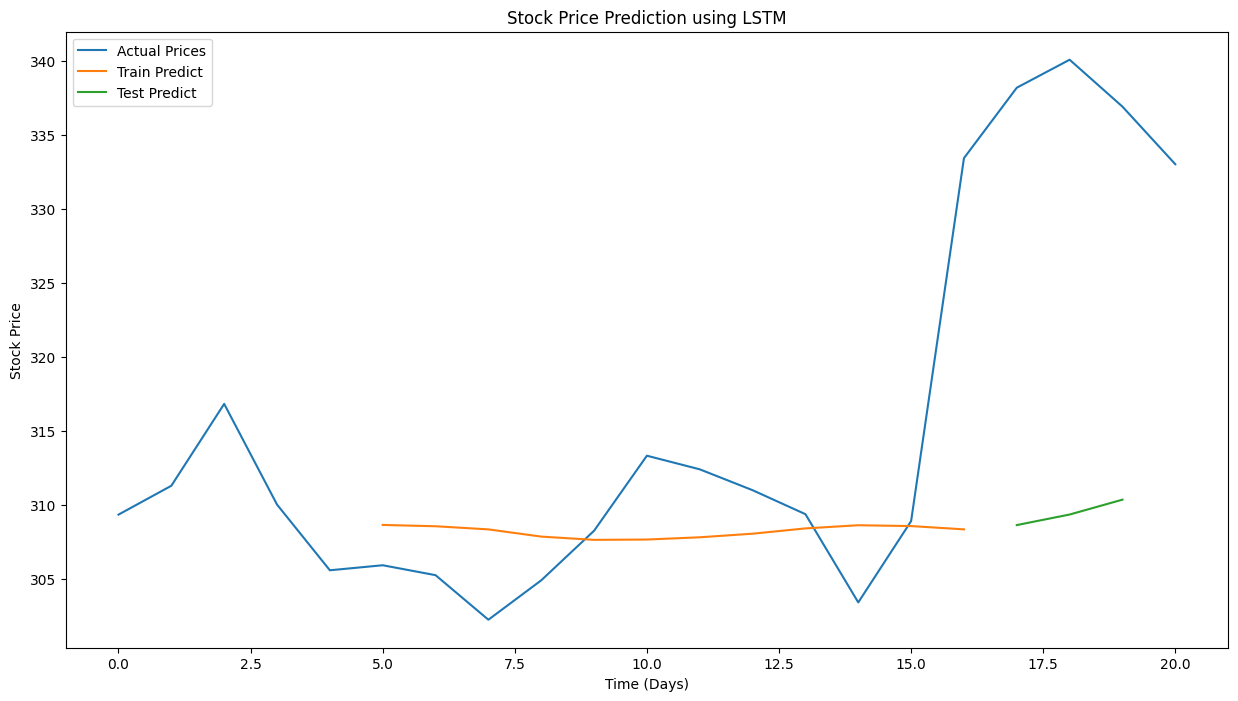

In [7]:
# Make predictions
train_predict = model.predict(X_train)
test_predict = model.predict(X_test)

# Inverse transform the predictions and actual values to original scale
train_predict = scaler.inverse_transform(train_predict)
y_train_inverse = scaler.inverse_transform(y_train.reshape(-1, 1))
test_predict = scaler.inverse_transform(test_predict)
y_test_inverse = scaler.inverse_transform(y_test.reshape(-1, 1))

# Prepare data for plotting
look_back = time_step

# Shift train predictions for plotting
train_plot = np.empty_like(scaled_data)
train_plot[:, :] = np.nan
train_plot[look_back:len(train_predict) + look_back, :] = train_predict

# Shift test predictions for plotting
test_plot = np.empty_like(scaled_data)
test_plot[:, :] = np.nan
# Corrected indexing for test_plot
test_plot[len(train_predict) + look_back : len(train_predict) + look_back + len(test_predict), :] = test_predict

# Plot actual vs. predicted values
plt.figure(figsize=(15, 8))
plt.plot(scaler.inverse_transform(scaled_data), label='Actual Prices')
plt.plot(train_plot, label='Train Predict')
plt.plot(test_plot, label='Test Predict')
plt.title('Stock Price Prediction using LSTM')
plt.xlabel('Time (Days)')
plt.ylabel('Stock Price')
plt.legend()
plt.show()

This concludes the implementation of the Stock Market Prediction using RNN/LSTM with your **uploaded historical stock data**. The model has been trained and evaluated, and the predictions are visualized above.